# Lab Assignment 11 – Explainable AI on Heart Failure Clinical Records
**Course:** CSET343 – AI in Healthcare
**Objective:** Analyse and process real-world healthcare data and use Explainable AI (SHAP) to understand a model's decisions.

**Dataset:** Heart Failure Clinical Records (Chicco & Jurman, 2020) – 299 patients, 12 clinical features, target `DEATH_EVENT` (1 = died during follow-up).

## Task 1 – Dataset acquisition
The Kaggle dataset (andrewmvd/heart-failure-clinical-data) is the same file published on the UCI Machine Learning Repository (dataset id 519). It was downloaded from UCI into `data/`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, ConfusionMatrixDisplay)
import shap
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
DATA_PATH = "data/heart_failure_clinical_records_dataset.csv"
print("pandas", pd.__version__, "| shap", shap.__version__)

pandas 2.2.3 | shap 0.52.0


## Task 2 – Load the dataset

In [2]:
df = pd.read_csv(DATA_PATH)
df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


## Task 3 – Summarise the dataset

In [3]:
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
print("\nData types:")
print(df.dtypes)
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nTotal missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

Rows: 299 | Columns: 13

Data types:
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object

Missing values per column:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64

Total missing values: 0
Duplicate rows: 0


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,299.0,60.83,11.89,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.43,0.50,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.84,970.29,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.42,0.49,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.08,11.83,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.35,0.48,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.03,97804.24,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.39,1.03,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.63,4.41,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.65,0.48,0.0,0.0,1.0,1.0,1.0


In [5]:
print("Target balance (DEATH_EVENT):")
print(df["DEATH_EVENT"].value_counts().rename({0: "survived (0)", 1: "died (1)"}))
print(f"Death rate: {df['DEATH_EVENT'].mean():.1%}")

Target balance (DEATH_EVENT):
DEATH_EVENT
survived (0)    203
died (1)         96
Name: count, dtype: int64
Death rate: 32.1%


**Feature types**

| Type | Columns |
|---|---|
| Continuous | age, creatinine_phosphokinase, ejection_fraction, platelets, serum_creatinine, serum_sodium, time |
| Binary (categorical) | anaemia, diabetes, high_blood_pressure, sex (1 = male), smoking |
| Target | DEATH_EVENT |

## Task 4 – Visualise missing values

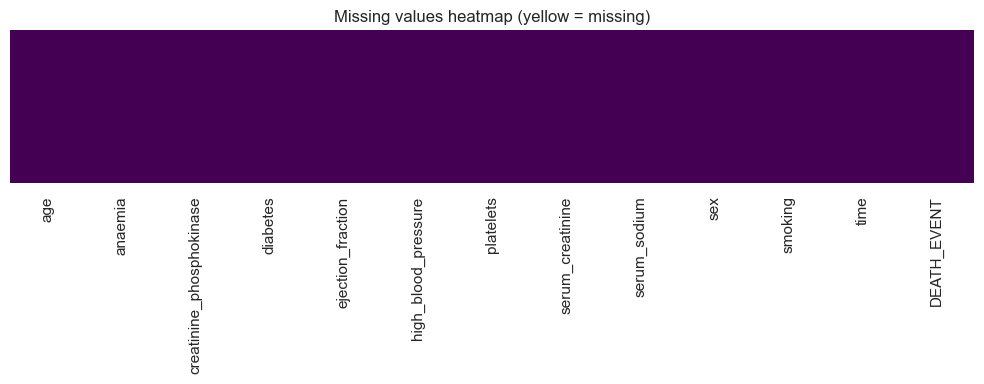

In [6]:
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing values heatmap (yellow = missing)")
plt.tight_layout(); plt.show()

The heatmap is a single colour: the original dataset has **no missing values**. Task 6 still applies the imputation strategy so the pipeline works on new data that does have gaps, and it is demonstrated on a copy with a few values removed on purpose.

## Task 5 – Plot distributions

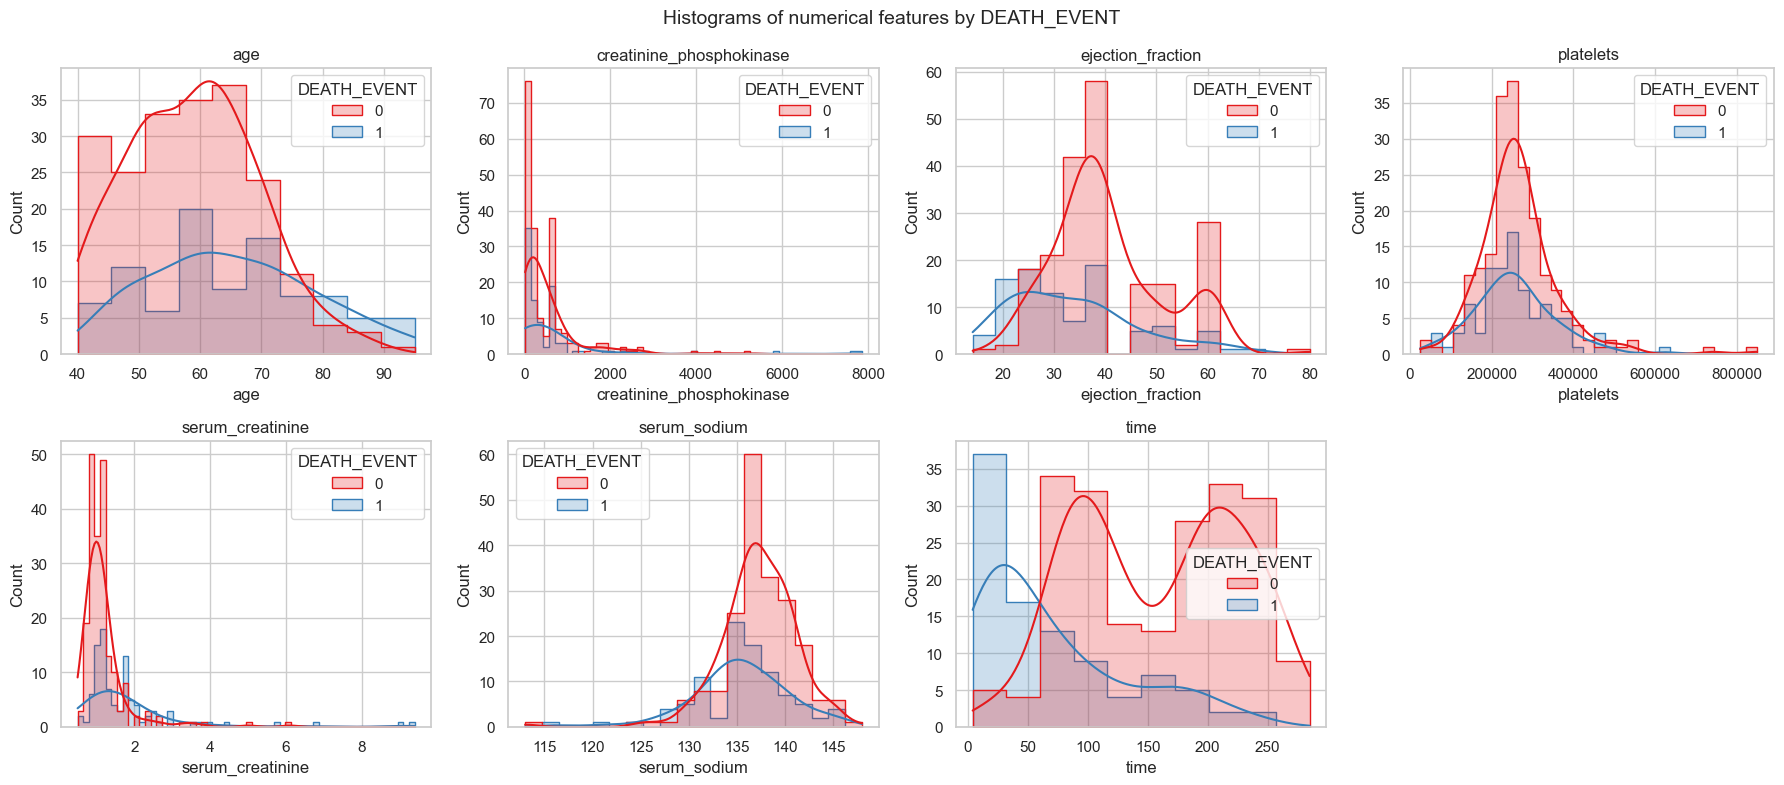

In [7]:
num_cols = ["age", "creatinine_phosphokinase", "ejection_fraction", "platelets", "serum_creatinine", "serum_sodium", "time"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(data=df, x=col, hue="DEATH_EVENT", kde=True, ax=ax, palette="Set1", element="step")
    ax.set_title(col)
axes.flat[-1].axis("off")
plt.suptitle("Histograms of numerical features by DEATH_EVENT", fontsize=14)
plt.tight_layout(); plt.show()

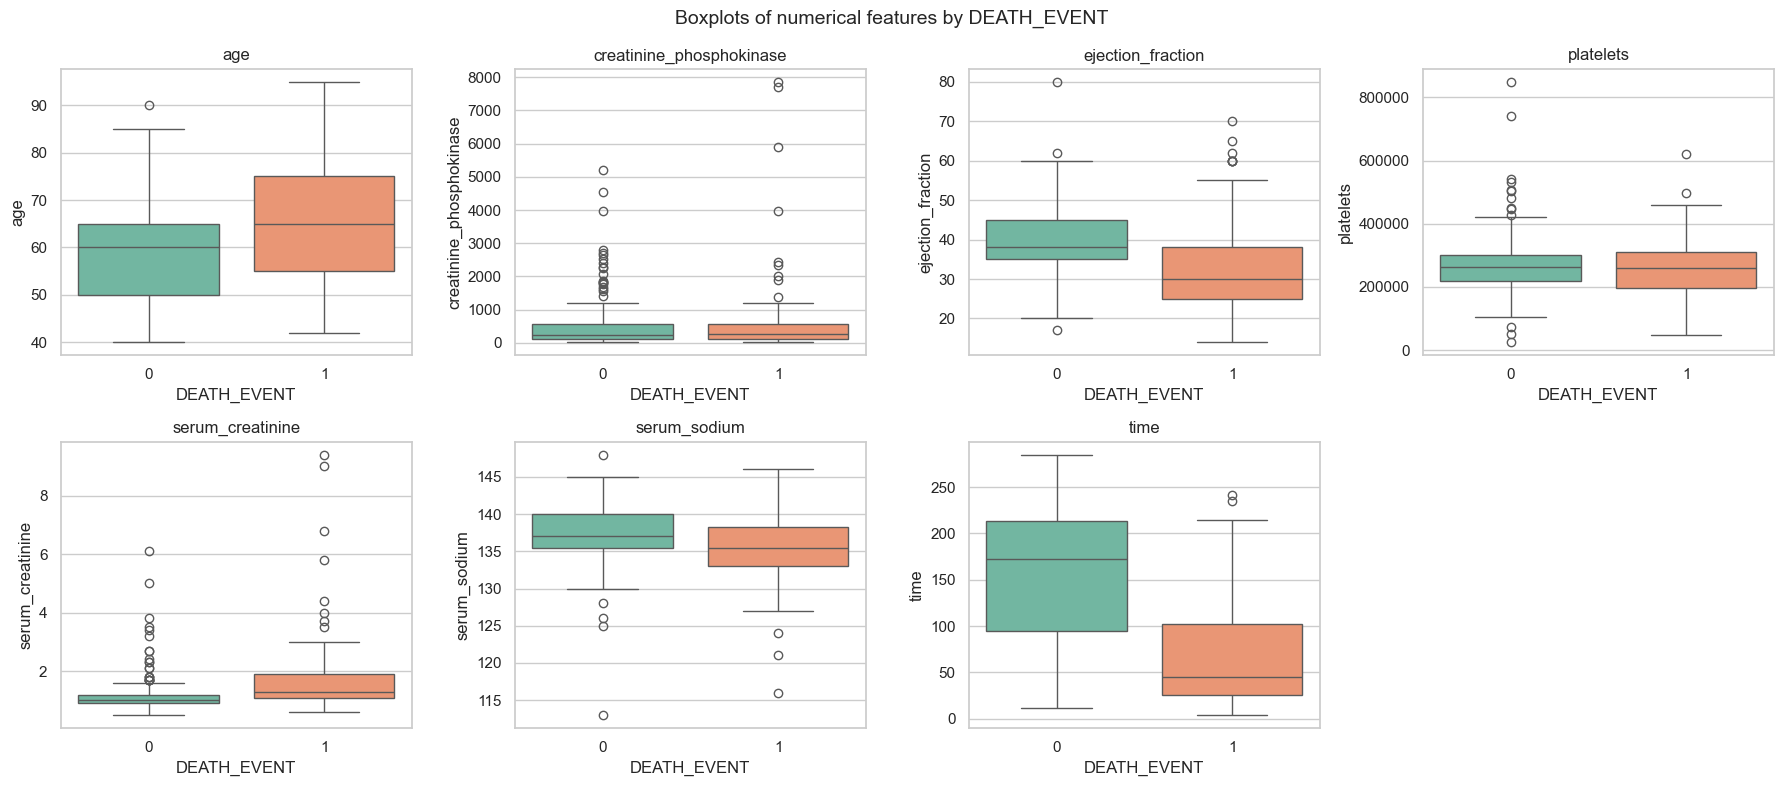

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(data=df, x="DEATH_EVENT", y=col, ax=ax, palette="Set2")
    ax.set_title(col)
axes.flat[-1].axis("off")
plt.suptitle("Boxplots of numerical features by DEATH_EVENT", fontsize=14)
plt.tight_layout(); plt.show()

**Observations**
- `creatinine_phosphokinase`, `serum_creatinine` and `platelets` are strongly right-skewed with long tails (many outliers).
- Patients who died tend to be older, have a lower `ejection_fraction`, higher `serum_creatinine` and a much shorter `time` (follow-up period).

## Tasks 6–8 – Impute missing values
Numerical features use the **median** (robust to the skew seen above); categorical (binary) features use the **mode**.

In [9]:
cat_cols = ["anaemia", "diabetes", "high_blood_pressure", "sex", "smoking"]

def impute(data):
    data = data.copy()
    for c in num_cols:
        data[c] = data[c].fillna(data[c].median())
    for c in cat_cols:
        data[c] = data[c].fillna(data[c].mode()[0])
    return data

# Demonstration: knock out a few values in a copy, then impute
demo = df.copy()
rng = np.random.default_rng(RANDOM_STATE)
for c in ["serum_creatinine", "smoking"]:
    demo.loc[rng.choice(demo.index, 10, replace=False), c] = np.nan
print("Missing before imputation:", demo[["serum_creatinine", "smoking"]].isnull().sum().to_dict())
demo = impute(demo)
print("Missing after imputation: ", demo[["serum_creatinine", "smoking"]].isnull().sum().to_dict())

# Apply to the real data (no-op here because nothing is missing)
df = impute(df)
print("Missing in real data after imputation:", int(df.isnull().sum().sum()))

Missing before imputation: {'serum_creatinine': 10, 'smoking': 10}
Missing after imputation:  {'serum_creatinine': 0, 'smoking': 0}
Missing in real data after imputation: 0


## Task 9 – Remove outliers
The IQR rule with the usual 1.5 × IQR fence would delete a large share of this small dataset (high creatinine and CPK values are clinically real, not errors). So only **extreme** outliers beyond **3 × IQR** are removed, on the skewed lab measurements.

In [10]:
def iqr_mask(s, k):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return s.between(q1 - k * iqr, q3 + k * iqr)

for k in (1.5, 3.0):
    m = np.logical_and.reduce([iqr_mask(df[c], k) for c in ["creatinine_phosphokinase", "platelets", "serum_creatinine"]])
    print(f"k = {k}: would keep {m.sum()} of {len(df)} rows (remove {len(df) - m.sum()})")

outlier_cols = ["creatinine_phosphokinase", "platelets", "serum_creatinine"]
keep = np.logical_and.reduce([iqr_mask(df[c], 3.0) for c in outlier_cols])
before = len(df)
df = df[keep].reset_index(drop=True)
print(f"\nRows before: {before} | after: {len(df)} | removed: {before - len(df)}")
print(f"Death rate after removal: {df['DEATH_EVENT'].mean():.1%}")

k = 1.5: would keep 228 of 299 rows (remove 71)
k = 3.0: would keep 263 of 299 rows (remove 36)

Rows before: 299 | after: 263 | removed: 36
Death rate after removal: 29.7%


## Task 10 – Correct inconsistencies
Check every column against valid clinical ranges and binary columns for values other than 0/1.

In [11]:
rules = {
    "age": (0, 120), "ejection_fraction": (5, 90), "serum_sodium": (100, 170),
    "serum_creatinine": (0.1, 15), "platelets": (10_000, 1_000_000), "creatinine_phosphokinase": (1, 10_000), "time": (0, 400),
}
for col, (lo, hi) in rules.items():
    bad = ~df[col].between(lo, hi)
    print(f"{col:26s} invalid entries: {int(bad.sum())}")
    df.loc[bad, col] = np.nan                       # mark invalid values as missing ...
for col in cat_cols + ["DEATH_EVENT"]:
    bad = ~df[col].isin([0, 1])
    print(f"{col:26s} non-binary entries: {int(bad.sum())}")
    df.loc[bad, col] = np.nan
df = impute(df)                                     # ... then re-impute them with median / mode
df["age"] = df["age"].round().astype(int)          # age stored as whole years (a few were 60.667)
for col in cat_cols + ["DEATH_EVENT"]:
    df[col] = df[col].astype(int)
print("\nDuplicates:", int(df.duplicated().sum()), "| Missing:", int(df.isnull().sum().sum()), "| Shape:", df.shape)

age                        invalid entries: 0
ejection_fraction          invalid entries: 0
serum_sodium               invalid entries: 0
serum_creatinine           invalid entries: 0
platelets                  invalid entries: 0
creatinine_phosphokinase   invalid entries: 0
time                       invalid entries: 0
anaemia                    non-binary entries: 0
diabetes                   non-binary entries: 0
high_blood_pressure        non-binary entries: 0
sex                        non-binary entries: 0
smoking                    non-binary entries: 0
DEATH_EVENT                non-binary entries: 0

Duplicates: 0 | Missing: 0 | Shape: (263, 13)


## Tasks 11–13 – Feature engineering

In [12]:
# Task 12: age_group with bins <40, 40-60, >60
df["age_group"] = pd.cut(df["age"], bins=[0, 39, 60, 200], labels=["<40", "40-60", ">60"])
print(df["age_group"].value_counts().sort_index())
print("Note: the youngest patient is", df["age"].min(), "so the <40 group is empty in this dataset.")

# Task 13: risk_score - low ejection fraction and high serum creatinine both mean higher risk,
# so the score is the normalised product of creatinine and (100 - ejection_fraction)
raw = df["serum_creatinine"] * (100 - df["ejection_fraction"])
df["risk_score"] = (raw - raw.min()) / (raw.max() - raw.min())
print("\nrisk_score summary:"); print(df["risk_score"].describe().round(3))
print("\nMean risk_score by outcome:"); print(df.groupby("DEATH_EVENT")["risk_score"].mean().round(3))

age_group
<40        0
40-60    137
>60      126
Name: count, dtype: int64
Note: the youngest patient is 40 so the <40 group is empty in this dataset.

risk_score summary:
count    263.000
mean       0.267
std        0.178
min        0.000
25%        0.148
50%        0.220
75%        0.340
max        1.000
Name: risk_score, dtype: float64

Mean risk_score by outcome:
DEATH_EVENT
0    0.217
1    0.387
Name: risk_score, dtype: float64


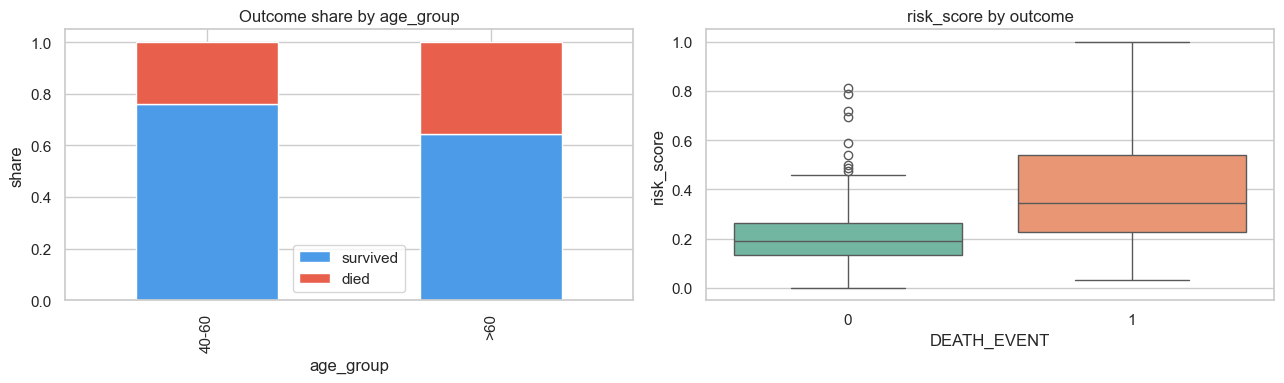

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pd.crosstab(df["age_group"], df["DEATH_EVENT"], normalize="index").plot(kind="bar", stacked=True, ax=axes[0], color=["#4c9be8", "#e8604c"])
axes[0].set_title("Outcome share by age_group"); axes[0].set_ylabel("share"); axes[0].legend(["survived", "died"])
sns.boxplot(data=df, x="DEATH_EVENT", y="risk_score", ax=axes[1], palette="Set2"); axes[1].set_title("risk_score by outcome")
plt.tight_layout(); plt.show()

## Task 14 – Encode categorical variables
`sex`, `smoking`, `anaemia`, `diabetes` and `high_blood_pressure` are already 0/1 (label-encoded). `sex` is renamed for readability, and `age_group` is one-hot encoded.

In [14]:
df = df.rename(columns={"sex": "sex_male"})
df = pd.get_dummies(df, columns=["age_group"], prefix="age", dtype=int)
print(df.columns.tolist())
df.head()

['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex_male', 'smoking', 'time', 'DEATH_EVENT', 'risk_score', 'age_<40', 'age_40-60', 'age_>60']


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex_male,smoking,time,DEATH_EVENT,risk_score,age_<40,age_40-60,age_>60
0,75,0,582.0,0,20.0,1,265000.0,1.9,130.0,1,0,4.0,1,0.667360,0,0,1
1,65,0,146.0,0,20.0,0,162000.0,1.3,129.0,1,1,7.0,1,0.417879,0,0,1
2,50,1,111.0,0,20.0,0,210000.0,1.9,137.0,1,0,7.0,1,0.667360,0,1,0
3,65,1,160.0,1,20.0,0,327000.0,2.7,116.0,0,0,8.0,1,1.000000,0,0,1
4,90,1,47.0,0,40.0,1,204000.0,2.1,132.0,1,1,8.0,1,0.532225,0,0,1


## Task 15 – Normalise features (MinMaxScaler)
**Leakage note:** `time` is the follow-up period, which is cut short when a patient dies. It is only known *after* the outcome, so it is dropped from the model inputs; keeping it would give an inflated, unusable score.
The scaler is fitted on the **training set only** and then applied to the test set, so no information from test patients leaks into training.

In [15]:
X = df.drop(columns=["DEATH_EVENT", "time"])
y = df["DEATH_EVENT"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

scale_cols = ["age", "creatinine_phosphokinase", "ejection_fraction", "platelets", "serum_creatinine", "serum_sodium"]
scaler = MinMaxScaler()
X_train = X_train.copy(); X_test = X_test.copy()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols] = scaler.transform(X_test[scale_cols])
print("Train:", X_train.shape, "| Test:", X_test.shape)
X_train[scale_cols].describe().loc[["min", "max"]].round(3)

Train: (197, 15) | Test: (66, 15)


,age,creatinine_phosphokinase,ejection_fraction,platelets,serum_creatinine,serum_sodium
min,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0


## Task 16 – Train a classifier
A Random Forest (with balanced class weights, since only about a third of patients died) is compared with a Logistic Regression baseline using 5-fold cross-validation on the training set.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=3,
                                            class_weight="balanced", random_state=RANDOM_STATE),
}
for name, m in models.items():
    auc = cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc")
    print(f"{name:20s} CV ROC-AUC = {auc.mean():.3f} ± {auc.std():.3f}")

Logistic Regression  CV ROC-AUC = 0.725 ± 0.065


Random Forest        CV ROC-AUC = 0.774 ± 0.071


Accuracy : 0.788
Precision: 0.650
Recall   : 0.650
F1-score : 0.650
ROC-AUC  : 0.828

              precision    recall  f1-score   support

    survived       0.85      0.85      0.85        46
        died       0.65      0.65      0.65        20

    accuracy                           0.79        66
   macro avg       0.75      0.75      0.75        66
weighted avg       0.79      0.79      0.79        66



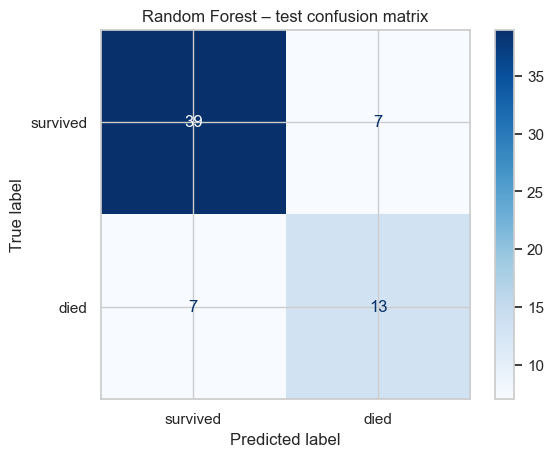

In [17]:
model = models["Random Forest"].fit(X_train, y_train)
pred = model.predict(X_test); proba = model.predict_proba(X_test)[:, 1]
print(f"Accuracy : {accuracy_score(y_test, pred):.3f}")
print(f"Precision: {precision_score(y_test, pred):.3f}")
print(f"Recall   : {recall_score(y_test, pred):.3f}")
print(f"F1-score : {f1_score(y_test, pred):.3f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, proba):.3f}\n")
print(classification_report(y_test, pred, target_names=["survived", "died"]))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["survived", "died"]).plot(cmap="Blues")
plt.title("Random Forest – test confusion matrix"); plt.show()

## Task 17 – Explainability with SHAP
SHAP (SHapley Additive exPlanations) gives each feature a contribution to each prediction. Positive SHAP value = pushes the prediction towards **death**; negative = towards **survival**. `TreeExplainer` computes exact values for tree models.

In [18]:
explainer = shap.TreeExplainer(model)
sv = explainer(X_test)
sv_died = sv[:, :, 1]          # explanations for class 1 (DEATH_EVENT = 1)
print("SHAP values shape (patients, features):", sv_died.values.shape)
print("Base value (average predicted death probability):", round(float(sv_died.base_values[0]), 3))

SHAP values shape (patients, features): (66, 15)
Base value (average predicted death probability): 0.5


### Global explanation – which features matter most overall

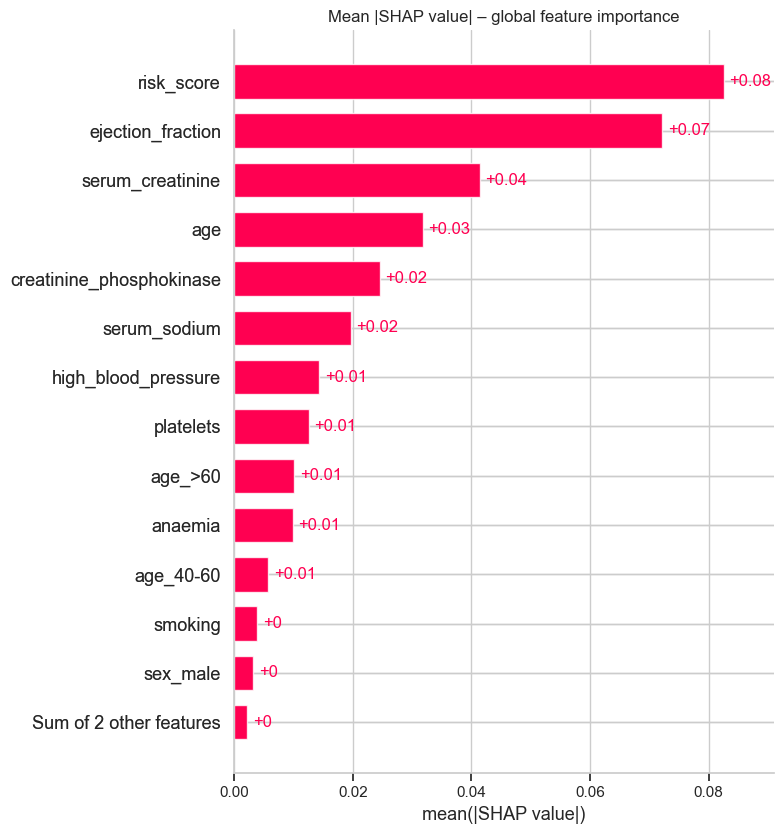

In [19]:
shap.plots.bar(sv_died, max_display=14, show=False)
plt.title("Mean |SHAP value| – global feature importance"); plt.tight_layout(); plt.show()

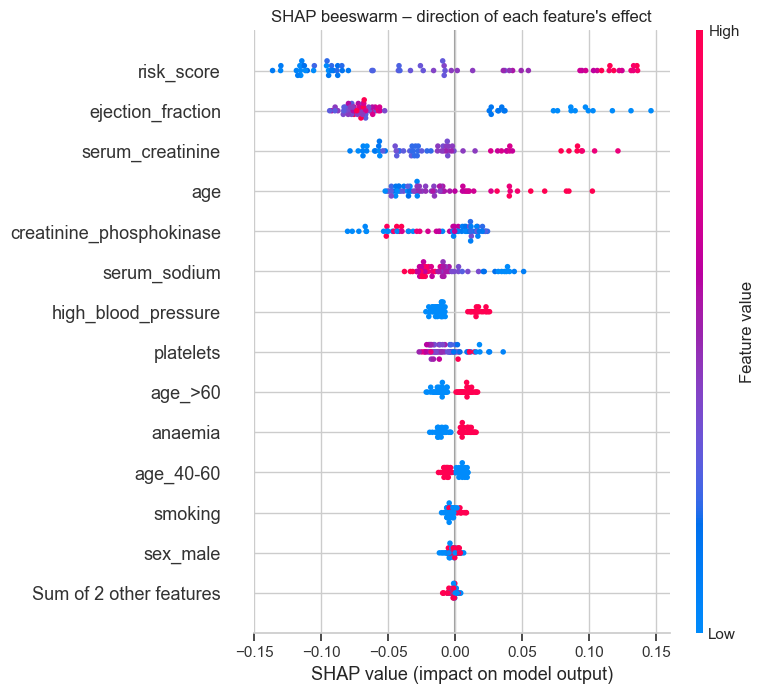

In [20]:
shap.plots.beeswarm(sv_died, max_display=14, show=False)
plt.title("SHAP beeswarm – direction of each feature's effect"); plt.tight_layout(); plt.show()

In [21]:
imp = pd.Series(np.abs(sv_died.values).mean(0), index=X_test.columns).sort_values(ascending=False)
print("Top features by mean |SHAP|:"); print(imp.round(4).head(8))

Top features by mean |SHAP|:
risk_score                  0.0826
ejection_fraction           0.0722
serum_creatinine            0.0414
age                         0.0318
creatinine_phosphokinase    0.0245
serum_sodium                0.0197
high_blood_pressure         0.0143
platelets                   0.0126
dtype: float64


### Dependence plots – how a feature's value changes its effect

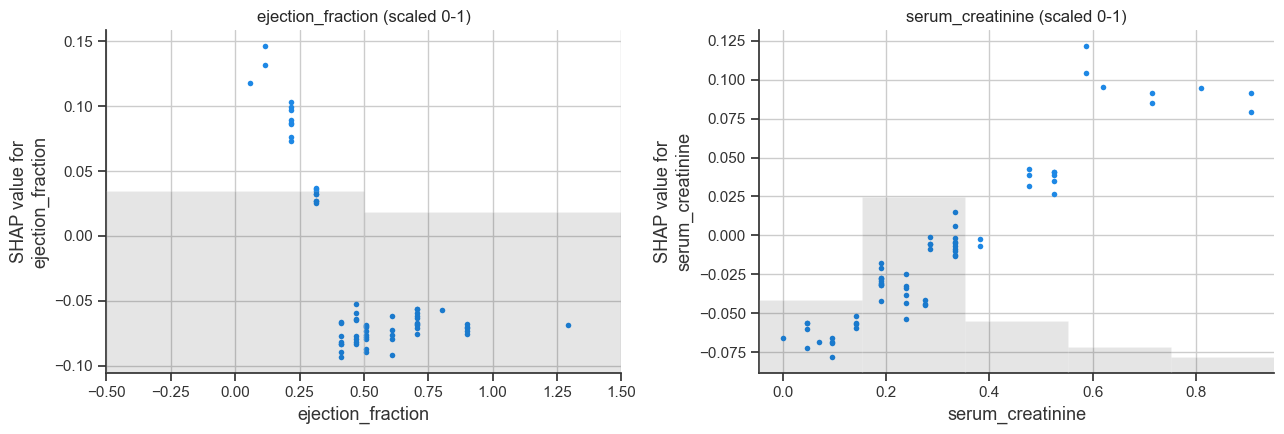

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
shap.plots.scatter(sv_died[:, "ejection_fraction"], ax=axes[0], show=False)
shap.plots.scatter(sv_died[:, "serum_creatinine"], ax=axes[1], show=False)
axes[0].set_title("ejection_fraction (scaled 0-1)"); axes[1].set_title("serum_creatinine (scaled 0-1)")
plt.tight_layout(); plt.show()

### Local explanation – why the model flagged one patient

Highest-risk test patient: predicted death probability = 0.81, actual = died
Lowest-risk test patient: predicted death probability = 0.10, actual = survived


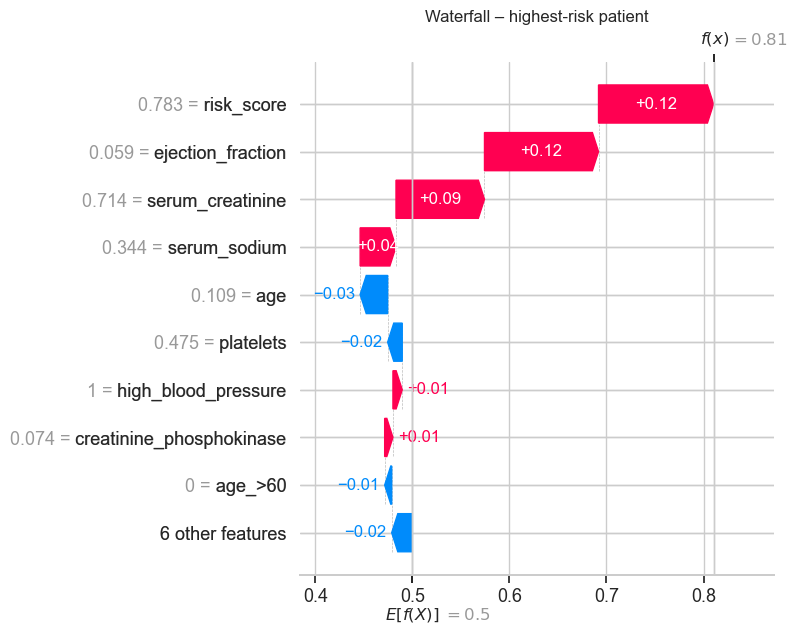

In [23]:
i_high = int(np.argmax(proba)); i_low = int(np.argmin(proba))
for label, i in [("Highest-risk test patient", i_high), ("Lowest-risk test patient", i_low)]:
    print(f"{label}: predicted death probability = {proba[i]:.2f}, actual = {'died' if y_test.iloc[i] else 'survived'}")
shap.plots.waterfall(sv_died[i_high], max_display=10, show=False)
plt.title("Waterfall – highest-risk patient"); plt.tight_layout(); plt.show()

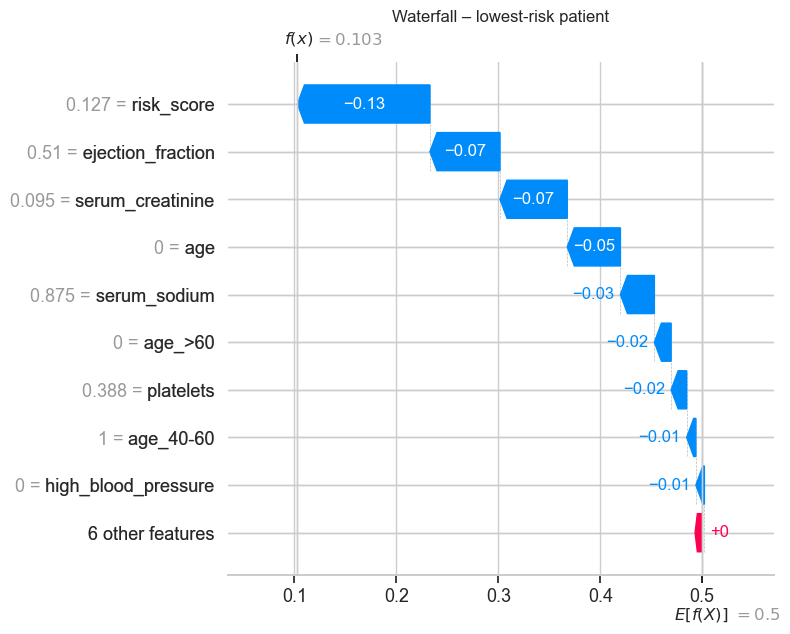

In [24]:
shap.plots.waterfall(sv_died[i_low], max_display=10, show=False)
plt.title("Waterfall – lowest-risk patient"); plt.tight_layout(); plt.show()

In [25]:
# Sanity check: SHAP is additive -> base value + sum of contributions = model output
recon = sv_died.base_values[i_high] + sv_died.values[i_high].sum()
print(f"base + sum(SHAP) = {recon:.4f} | model probability = {proba[i_high]:.4f}")

base + sum(SHAP) = 0.8103 | model probability = 0.8103
